# T12 · entrenamiento reanudable en Colab

Un modelo y una semilla por ejecución. Se conservan los cuatro perfiles,
la partición train/val/test, 10.001 actualizaciones y el calendario de LR.
Solo se usa validación durante el entrenamiento; test queda reservado.

**Primera sesión:** deja `REANUDAR_DESDE` vacío en la celda 4.
**Después de un corte:** abre este mismo notebook, elige la misma variante y
semilla y escribe la ruta relativa de `entrenamiento.pt` que se imprimió,
por ejemplo `speech_comparacion_t4/ID_RUN/entrenamiento.pt`.
Ejecuta otra vez las celdas 1–9. La reanudación conserva optimizador,
muestreo, azar, historia y mejor checkpoint, sin reiniciar el presupuesto.

Los `mejor_val.pt` y `ultimo.pt` de runs antiguos son pesos de inferencia:
no contienen el estado completo necesario para reanudar.

Los notebooks 04–10 y sus salidas se conservan. Este notebook se ejecuta
solo en Colab; el proyecto tiene suspendidos los cálculos GPU locales.


In [6]:
#@title 1. Comprobar que estamos en Colab con GPU
from pathlib import Path
import os
import subprocess
import sys

try:
    import google.colab
except ImportError as error:
    raise RuntimeError("Abre este notebook en Google Colab; no se ejecuta en el PC local.") from error

COLAB_BASE = globals().get("COLAB_BASE", Path.cwd().resolve())
PROJECT = COLAB_BASE / "tic_proyecto_reanudable_colab"
try:
    subprocess.run(["nvidia-smi", "--query-gpu=name,memory.total,driver_version", "--format=csv"], check=True)
except (FileNotFoundError, subprocess.CalledProcessError) as error:
    raise RuntimeError("Selecciona una GPU en Entorno de ejecución → Cambiar tipo de entorno de ejecución y vuelve a empezar.") from error
print("La instalación, preparación y entrenamiento se ejecutarán en la máquina de Colab.")


La instalación, preparación y entrenamiento se ejecutarán en la máquina de Colab.


## Fuentes y protocolo

El snapshot incluye el motor de reanudación, los cuatro perfiles, el plan
de semillas y el lock de dependencias. Se comprueba cada archivo con SHA-256.
No incluye grabaciones, pesos, credenciales ni acceso a GitHub.
Al reanudar se comprueban también las fuentes críticas y la configuración.


In [7]:
#@title 2. Copiar el código del proyecto (snapshot incluido)
import base64
import hashlib
import io
import json
from pathlib import PurePosixPath
from zipfile import ZipFile

SOURCE_SHA256 = 'b5d466839c6370d81d6d17d4c77c11feda8bb5e195f340e7b66f2173f3d43397'
SOURCE_B64 = (
    '...'
)

SOURCE_BYTES = base64.b64decode(SOURCE_B64)
if hashlib.sha256(SOURCE_BYTES).hexdigest() != SOURCE_SHA256:
    raise ValueError("El paquete de código no supera su SHA-256.")
PROJECT.mkdir(parents=True, exist_ok=True)
with ZipFile(io.BytesIO(SOURCE_BYTES)) as archive:
    for member in archive.infolist():
        relative = PurePosixPath(member.filename)
        if relative.is_absolute() or ".." in relative.parts or member.is_dir():
            raise ValueError(f"Ruta inesperada en el paquete: {member.filename}")
        destination = PROJECT.joinpath(*relative.parts)
        destination.parent.mkdir(parents=True, exist_ok=True)
        destination.write_bytes(archive.read(member))
SOURCE_MANIFEST = json.loads((PROJECT / "source_snapshot.json").read_text())
for name, expected in SOURCE_MANIFEST["files"].items():
    if hashlib.sha256((PROJECT / name).read_bytes()).hexdigest() != expected:
        raise ValueError(f"Código distinto del snapshot: {name}")
print("Código preparado:", len(SOURCE_MANIFEST["files"]), "archivos")
print("Commit base:", SOURCE_MANIFEST["git_commit_base"])
print("SHA-256 del paquete:", SOURCE_SHA256)


Código preparado: 59 archivos
Commit base: ed7a7827ccfb433f722baefc901fb1b603b2f349
SHA-256 del paquete: b5d466839c6370d81d6d17d4c77c11feda8bb5e195f340e7b66f2173f3d43397


## Entorno aislado y reproducible

Python 3.12.11, uv 0.9.4 y PyTorch 2.5.1 con CUDA 12.4, separados del kernel.
El lock fija las dependencias transitivas. El entorno numérico se registra
y se comprueba al reanudar. Una GPU de otro modelo queda indicada; no se
promete igualdad bit a bit entre hardware diferente.


In [8]:
#@title 3. Instalar el entorno del proyecto
import shutil

subprocess.run([sys.executable, "-m", "pip", "install", "--disable-pip-version-check", "uv==0.9.4"], check=True)
UV = shutil.which("uv")
if UV is None:
    raise RuntimeError("No se encontró uv después de instalarlo.")
PYTHON = PROJECT / ".venv" / "bin" / "python"
if not PYTHON.is_file():
    subprocess.run([UV, "venv", "--python", "3.12.11", "--seed", str(PROJECT / ".venv")], check=True)
subprocess.run([UV, "pip", "install", "--python", str(PYTHON), "--index-url", "https://download.pytorch.org/whl/cu124",
                "torch==2.5.1", "torchvision==0.20.1"], cwd=PROJECT, check=True)
subprocess.run([UV, "pip", "install", "--python", str(PYTHON), "-r", "requirements-e1.lock"], cwd=PROJECT, check=True)
subprocess.run([UV, "pip", "check", "--python", str(PYTHON)], cwd=PROJECT, check=True)

def ejecutar(argumentos: list[str]) -> None:
    """Muestra stdout/stderr en Colab y conserva el motivo real si falla."""
    from collections import deque
    import signal

    recent = deque(maxlen=25)
    process = subprocess.Popen([str(PYTHON), *argumentos], cwd=PROJECT,
                               stdout=subprocess.PIPE, stderr=subprocess.STDOUT,
                               text=True, encoding="utf-8", errors="replace", bufsize=1)
    try:
        for line in process.stdout:
            print(line, end="", flush=True)
            recent.append(line)
        returncode = process.wait()
    finally:
        if process.poll() is None:
            process.send_signal(signal.SIGINT)
            try:
                process.wait(timeout=30)
            except subprocess.TimeoutExpired:
                process.terminate()
                try:
                    process.wait(timeout=10)
                except subprocess.TimeoutExpired:
                    process.kill()
                    process.wait()
        process.stdout.close()
    if returncode:
        detail = "".join(recent).strip() or "El proceso terminó sin producir salida."
        raise RuntimeError(f"Falló {argumentos[0]} (código {returncode}).\n{detail}")

print("Entorno aislado preparado. No hace falta reiniciar el kernel.")


Entorno aislado preparado. No hace falta reiniciar el kernel.


## Elegir variante, semilla y estado guardado

La variante y semilla deben ser las mismas del run que se reanuda. El
presupuesto sigue siendo 10.001 pasos en total, sumando las sesiones.
`REANUDAR_DESDE` es relativa a la carpeta `checkpoints` de Drive y debe
terminar en `entrenamiento.pt`. Copia la carpeta del run completa si la mueves.

Los estados se confirman cada 250 pasos, desde el primero, y al finalizar
o pausar normalmente. Los pasos posteriores al último estado confirmado
pueden repetirse tras un corte. La cadencia y un límite opcional de pasos
por sesión viven en `configs/speech_reanudacion.yaml`, sin cambiar el LR.


In [24]:
#@title 4. Conectar Drive y preparar la configuración
CARPETA_DRIVE = "speech_bci" #@param {type:"string"}
VARIANTE = "conjunta_235" #@param ["baseline_5", "conjunta_235", "control_2", "control_3"]
INDICE_SEMILLA = 0 #@param {type:"integer"}
REANUDAR_DESDE = "" #@param {type:"string"}
# Índice de la lista de semillas de configs/speech_comparativa.yaml.

from datetime import datetime
from zoneinfo import ZoneInfo
from uuid import uuid4
from google.colab import drive
import json

relative = Path(CARPETA_DRIVE)
if not CARPETA_DRIVE.strip() or relative.is_absolute() or ".." in relative.parts:
    raise ValueError("Indica una carpeta relativa a Mi unidad, por ejemplo speech_bci.")
DRIVE_MOUNT = COLAB_BASE / "drive"
drive.mount(str(DRIVE_MOUNT))
DRIVE_ROOT = DRIVE_MOUNT / "MyDrive" / relative
EXPERIMENT_ID = datetime.now(ZoneInfo("Europe/Madrid")).strftime("%Y%m%d_%H%M%S") + "_" + uuid4().hex[:8]
RESULTS = DRIVE_ROOT / "experimentos" / ("reanudable_t12_" + EXPERIMENT_ID)
RESULTS.mkdir(parents=True, exist_ok=False)
CHECKPOINTS = DRIVE_ROOT / "checkpoints"
CHECKPOINTS.mkdir(parents=True, exist_ok=True)
link = PROJECT / "checkpoints"
if link.is_symlink():
    if link.resolve() != CHECKPOINTS.resolve():
        raise RuntimeError("El enlace de checkpoints apunta a otra carpeta. Usa el mismo CARPETA_DRIVE o una sesión nueva.")
elif link.exists():
    raise RuntimeError("Existe una carpeta local checkpoints. Revísala antes de crear el enlace a Drive.")
else:
    link.symlink_to(CHECKPOINTS, target_is_directory=True)

CONFIG = "configs/speech_colab.yaml"
ejecutar(["scripts/configure_speech_resume.py", "--variant", VARIANTE,
          "--seed-index", str(INDICE_SEMILLA), "--output", CONFIG])
config_code = """
from pathlib import Path
import json
import sys
import yaml
cfg = yaml.safe_load(Path(sys.argv[1]).read_text())
cfg['experimento']['nombre'] = cfg['experimento']['nombre'].removesuffix('_pytorch') + '_colab'
cfg['ejecucion']['dispositivo'] = 'cuda'
Path('configs/speech_colab.yaml').write_text(yaml.safe_dump(cfg, sort_keys=False), encoding='utf-8')
print(json.dumps(cfg))
"""
cfg = json.loads(subprocess.check_output([str(PYTHON), "-c", config_code, CONFIG], cwd=PROJECT, text=True))
for variable in ("OMP_NUM_THREADS", "MKL_NUM_THREADS", "OPENBLAS_NUM_THREADS"):
    os.environ[variable] = str(cfg["ejecucion"]["hilos_cpu"])
(RESULTS / "source_snapshot.json").write_text(json.dumps(SOURCE_MANIFEST, indent=2))
(RESULTS / "fuentes.zip").write_bytes(SOURCE_BYTES)
shutil.copyfile(PROJECT / CONFIG, RESULTS / "config.yaml")
print("Resultados:", RESULTS)
print("Checkpoints:", CHECKPOINTS)
print("Modelo:", cfg["modelo"])
print("Lote efectivo:", cfg["datos"]["batch_size"], "| microlote:", cfg["entrenamiento"]["micro_batch_size"])
print("Variante:", cfg["comparacion"]["variante"], "| semilla:", cfg["experimento"]["seed"])
print("Perfil:", cfg["comparacion"]["config_base"])
print("Actualizaciones máximas:", cfg["entrenamiento"]["pasos"], "| límite suave (s):", cfg["entrenamiento"].get("max_segundos"))
print("Microlote train:", cfg["entrenamiento"]["micro_batch_size"], "| evaluación:", cfg["evaluacion"]["micro_batch_size"])
print("W&B:", cfg["wandb"]["proyecto"], "|", cfg["wandb"]["modo"])

shutil.copyfile(PROJECT / cfg["protocolo"]["manifiesto"], RESULTS / "particion_t12_v1.json")
print("Protocolo fijo:", cfg["protocolo"]["sha256"])

RESUME_ARGUMENT = None
RESUME_FILE = None
if REANUDAR_DESDE.strip():
    relative_state = Path(REANUDAR_DESDE.strip())
    if relative_state.is_absolute() or ".." in relative_state.parts or relative_state.name != "entrenamiento.pt":
        raise ValueError("Indica una ruta relativa a checkpoints que termine en entrenamiento.pt.")
    RESUME_FILE = CHECKPOINTS / relative_state
    if not RESUME_FILE.is_file():
        raise FileNotFoundError(f"No se encuentra el estado en Drive: {RESUME_FILE}")
    RESUME_ARGUMENT = (Path("checkpoints") / relative_state).as_posix()
    info = RESUME_FILE.with_suffix(".json")
    if info.is_file():
        print("Estado orientativo guardado:", info.read_text())
    print("Se reanudará:", REANUDAR_DESDE)
else:
    print("Se iniciará un run nuevo desde cero.")
print("Persistencia:", cfg["reanudacion"])


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Perfil reanudable: conjunta_235; semilla 0; presupuesto 10001 pasos. Configuración: configs/speech_colab.yaml
Resultados: /content/drive/MyDrive/speech_bci/experimentos/reanudable_t12_20261029_134938_60a57966
Checkpoints: /content/drive/MyDrive/speech_bci/checkpoints
Modelo: {'nombre': 'speech_gru', 'entrada': 256, 'capa_dia': 256, 'capas': 5, 'unidades': 1024, 'bidireccional': False, 'kernel': 32, 'stride': 4, 'dropout_entrada': 0.2, 'dropout_gru': 0.4, 'salidas_intermedias': [2, 3]}
Lote efectivo: 64 | microlote: 16
Variante: conjunta_235 | semilla: 0
Perfil: configs/speech_salidas_t4.yaml
Actualizaciones máximas: 10001 | límite suave (s): None
Microlote train: 16 | evaluación: 16
W&B: tiiac-2026 | online
Protocolo fijo: d9043f30f4755dfef1bdfa33f454ea7025c638ae01cb8a49e182ac1aaf62ccdb
Se iniciará un run nuevo desde cero.
Persistencia: {'cada_pasos': 250, 'm

In [10]:
#@title 5. Comprobar CUDA y registrar el entorno
probe = """
import json
import platform
import sys
import torch
import numpy
import wandb
if not torch.cuda.is_available():
    raise RuntimeError('El Python del proyecto no detecta CUDA. Comprueba que Colab tiene GPU.')
major, minor = torch.cuda.get_device_capability()
maximum = max(int(name.removeprefix('sm_')) // 10 for name in torch.cuda.get_arch_list() if name.startswith('sm_'))
if major > maximum:
    raise RuntimeError('La GPU asignada necesita un PyTorch más reciente. Para conservar torch 2.5.1 usa una T4, L4 o A100 si están disponibles.')
print(json.dumps({'python': sys.version, 'platform': platform.platform(), 'torch': str(torch.__version__),
                  'numpy': numpy.__version__, 'wandb': wandb.__version__, 'cuda': torch.version.cuda,
                  'gpu': torch.cuda.get_device_name(), 'capability': [major, minor],
                  'gpu_total_mib': torch.cuda.get_device_properties(0).total_memory / (1 << 20)}, indent=2))
"""
environment = json.loads(subprocess.check_output([str(PYTHON), "-c", probe], cwd=PROJECT, text=True))
(RESULTS / "entorno.json").write_text(json.dumps(environment, indent=2))
freeze = subprocess.check_output([str(PYTHON), "-m", "pip", "freeze"], cwd=PROJECT, text=True)
(RESULTS / "paquetes.txt").write_text(freeze)
print(json.dumps(environment, indent=2))
print("Espacio libre en Colab:", round(shutil.disk_usage(PROJECT).free / (1 << 30), 1), "GiB")


{
  "python": "3.12.11 (main, Oct  7 2025, 15:34:39) [Clang 20.1.4 ]",
  "platform": "Linux-6.6.159+-x86_64-with-glibc2.39",
  "torch": "2.5.1+cu124",
  "numpy": "2.1.3",
  "wandb": "0.18.7",
  "cuda": "12.4",
  "gpu": "NVIDIA A100-SXM4-40GB",
  "capability": [
    8,
    0
  ],
  "gpu_total_mib": 40441.375
}
Espacio libre en Colab: 187.4 GiB


## Preparar los mismos datos

Se usa `competitionData.tar.gz` (**3,67 GB**) y se verifica el tamaño y
SHA-256 oficial antes de extraer. El archivo completo ocupa unos **6,95 GB
extraído** y la caché seleccionada añade **2,44 GB**. No se usa holdout para
entrenar o medir PER. La preparación ejecuta los scripts del repositorio:
fonemas con g2p-en, estadísticas solo de las 5.180 frases train y señales NPY por sesión.
Se aplica la partición incluida de 1.460 frases de validación. El test queda
preparado para su evaluación posterior; no se usa para seleccionar pesos.

En la celda siguiente, **Drive** usa el archivo que ya tengas subido. Busca
primero en `CARPETA_DRIVE/datos/`, `CARPETA_DRIVE/` y la raíz de Mi unidad;
después busca por nombre en otras carpetas de Mi unidad, con un límite de
5 niveles, 200 carpetas y 15 segundos entre accesos. Reconoce también nombres
como `competitionData (1).tar.gz`. Si hay varios candidatos, muestra sus rutas.

Puedes evitar la búsqueda: en el panel **Archivos** de Colab, localiza el
archivo dentro de `drive`, pulsa con el botón derecho **Copiar ruta** y pega
el resultado en `ARCHIVO_DATOS_DRIVE`. Acepta esa ruta completa o una ruta
relativa a Mi unidad, como `speech_bci/datos/competitionData.tar.gz`.
Si no aparece, comprueba que montaste la misma cuenta de Drive donde está
subido. Para unidades compartidas, indica la ruta completa del panel Archivos.
No hace falta volver a subirlo ni reinstalar el entorno.

**Drive no intenta descargar de Dryad si no encuentra el archivo.** Para
intentar la descarga pública, selecciona expresamente **Dryad**. La salida
de los scripts incluye el motivo real si fallan. Una copia de Drive solo
sustituye la copia local después de verificar el SHA-256 oficial; una copia
local ya verificada se reutiliza. No subas el archivo grande mediante el
formulario del notebook.


In [11]:
#@title 6. Obtener y extraer competitionData
ORIGEN_DATOS = "Drive" #@param ["Drive", "Dryad"]
ARCHIVO_DATOS_DRIVE = "" #@param {type:"string"}


def buscar_archivos_drive(root: Path) -> tuple[list[Path], bool]:
    """Busca el tar de competitionData por nombre, sin leer su contenido."""
    import time

    matches = []
    started = time.monotonic()
    visited = 0
    incomplete = False
    errors = []
    for current, directories, filenames in os.walk(root, onerror=errors.append, followlinks=False):
        visited += 1
        folder = Path(current)
        if len(folder.relative_to(root).parts) >= 5:
            incomplete = incomplete or bool(directories)
            directories.clear()
        else:
            directories[:] = sorted(name for name in directories if not name.startswith('.'))
        for name in sorted(filenames):
            if name.casefold().startswith('competitiondata') and name.casefold().endswith(('.tar.gz', '.tgz')):
                matches.append(folder / name)
        if visited >= 200 or time.monotonic() - started >= 15:
            incomplete = True
            break
    return matches, incomplete or bool(errors)


manifest = json.loads((PROJECT / "docs/datasets/speech_2023/manifest.json").read_text())
expected = next(item for item in manifest["files"] if item["name"] == "competitionData.tar.gz")
destination = PROJECT / "data" / "speech_2023" / expected["name"]
destination.parent.mkdir(parents=True, exist_ok=True)
my_drive = DRIVE_MOUNT / "MyDrive"
print("Tamaño esperado:", expected["size_bytes"], "bytes")
print("Espacio libre en Colab:", round(shutil.disk_usage(PROJECT).free / (1 << 30), 1), "GiB")
if ORIGEN_DATOS not in ("Drive", "Dryad"):
    raise ValueError("Selecciona Drive o Dryad en ORIGEN_DATOS.")

local_valid = False
if destination.is_file():
    try:
        ejecutar(["scripts/get_data.py", "--dataset", "speech_2023", "--files", expected["name"], "--verify-only"])
        local_valid = True
        print("Se reutiliza la copia local verificada.")
    except RuntimeError:
        print("La copia local no es válida; solo se sustituirá por un archivo verificado.")

if not local_valid and ORIGEN_DATOS == "Drive":
    if not my_drive.is_dir():
        raise RuntimeError("Drive no está disponible. Ejecuta la celda 4 para montarlo antes de continuar.")
    entered = ARCHIVO_DATOS_DRIVE.strip().strip("\"'")
    if entered:
        selected = Path(entered)
        if ".." in selected.parts:
            raise ValueError("Indica la ruta del archivo sin componentes '..'.")
        if selected.is_absolute():
            if not selected.is_relative_to(DRIVE_MOUNT):
                raise ValueError(f"La ruta debe estar dentro del Drive montado en {DRIVE_MOUNT}.")
            source = selected
        elif selected.parts and selected.parts[0] in ("MyDrive", "Shareddrives"):
            source = DRIVE_MOUNT / selected
        else:
            source = my_drive / selected
        if not source.is_file():
            raise FileNotFoundError(
                f"Colab no ve un archivo en: {source}\n"
                "En el panel Archivos, localízalo dentro de drive y usa 'Copiar ruta'. "
                "Comprueba que Drive está montado con la cuenta donde subiste el archivo. "
                "No se ha intentado descargar de Dryad."
            )
    else:
        candidates = [DRIVE_ROOT / "datos" / expected["name"], DRIVE_ROOT / expected["name"], my_drive / expected["name"]]
        source = next((candidate for candidate in candidates if candidate.is_file()), None)
        if source is None:
            print("Buscando competitionData en Mi unidad (hasta 5 niveles y 200 carpetas)...", flush=True)
            matches, incomplete = buscar_archivos_drive(my_drive)
            if incomplete:
                print("Búsqueda limitada: puede haber otras carpetas. Puedes indicar la ruta exacta.")
            complete = [candidate for candidate in matches if candidate.stat().st_size == expected["size_bytes"]]
            choices = complete or matches
            if len(choices) == 1:
                source = choices[0]
            else:
                if choices:
                    detail = "Se han encontrado varios archivos:\n" + "\n".join(str(candidate) for candidate in choices)
                else:
                    detail = "No se encontró el archivo. Rutas iniciales comprobadas:\n" + "\n".join(str(candidate) for candidate in candidates)
                raise RuntimeError(
                    f"{detail}\n\nEn el panel Archivos de Colab, localiza el archivo dentro de drive, "
                    "pulsa 'Copiar ruta' y pégala en ARCHIVO_DATOS_DRIVE. "
                    "Comprueba la cuenta de Drive si no aparece en el panel. "
                    "Vuelve a ejecutar solo esta celda. No se ha intentado descargar de Dryad."
                )
    print("Archivo encontrado en Drive:", source, flush=True)
    size = source.stat().st_size
    if size != expected["size_bytes"]:
        raise ValueError(f"El archivo de Drive tiene {size} bytes; se esperaban {expected['size_bytes']}. Comprueba que terminó la subida y que es el archivo original del 1 de septiembre de 2023.")
    temporary = destination.with_name(destination.name + ".drive.part")
    print("Copiando al disco de Colab; después se comprobará el SHA-256...", flush=True)
    shutil.copyfile(source, temporary)
    verification = """
from pathlib import Path
import sys
from scripts.get_data import leer_manifiesto, verificar
source = next(item for item in leer_manifiesto('speech_2023')['files'] if item['name'] == 'competitionData.tar.gz')
verificar(Path(sys.argv[1]), source)
print('Copia de Drive: tamaño y SHA-256 oficiales verificados.')
"""
    ejecutar(["-c", verification, str(temporary)])
    temporary.replace(destination)
elif not local_valid:
    ejecutar(["scripts/get_data.py", "--dataset", "speech_2023", "--files", expected["name"]])

extract = """
from pathlib import Path
import json
import tarfile
import yaml
cfg = yaml.safe_load(Path('configs/speech_colab.yaml').read_text())
manifest = json.loads(Path('docs/datasets/speech_2023/manifest.json').read_text())
digest = next(item['sha256'] for item in manifest['files'] if item['name'] == 'competitionData.tar.gz')
marker = Path('data/speech_2023/.extraccion_verificada')
expected = [Path(cfg['datos']['raiz']) / split / (session + '.mat') for split in ['train', 'test'] for session in cfg['datos']['sesiones']]
if not marker.exists() or marker.read_text().strip() != digest or not all(path.is_file() for path in expected):
    with tarfile.open('data/speech_2023/competitionData.tar.gz') as archive:
        archive.extractall('data/speech_2023', filter='data')
    marker.write_text(digest)
print('Extraídas las señales originales. Las 19 sesiones seleccionadas están disponibles.')
"""
ejecutar(["-c", extract])


Tamaño esperado: 3669638707 bytes
Espacio libre en Colab: 187.4 GiB
Archivo encontrado en Drive: /content/drive/MyDrive/speech_bci/datos/competitionData.tar.gz
Copiando al disco de Colab; después se comprobará el SHA-256...
Copia de Drive: tamaño y SHA-256 oficiales verificados.
Extraídas las señales originales. Las 19 sesiones seleccionadas están disponibles.


In [12]:
#@title 7. Preparar recursos, fonemas y señales
REHACER_PREPARACION = False #@param {type:"boolean"}

ejecutar(["scripts/get_phoneme_resources.py", "--config", CONFIG])
labels = PROJECT / cfg["etiquetas"]["salida"] / "manifest.json"
signals = PROJECT / cfg["datos"]["preparados"] / "manifest.json"
if REHACER_PREPARACION or not labels.is_file():
    ejecutar(["scripts/prepare_phoneme_labels.py", "--config", CONFIG])
if REHACER_PREPARACION or not signals.is_file():
    ejecutar(["scripts/prepare_speech_data.py", "--config", CONFIG])
verify = """
from pathlib import Path
import json
import yaml
from src.data.speech_dataset import SpeechDataset
from src.data.speech_protocol import read_speech_protocol
cfg = yaml.safe_load(Path('configs/speech_colab.yaml').read_text())
protocol = read_speech_protocol(cfg)
train = SpeechDataset(cfg, 'train')
val = SpeechDataset(cfg, 'val')
if (len(train), len(val), len(train.sessions)) != (5180, 1460, 19):
    raise ValueError('Los datos no corresponden al protocolo T12 fijado.')
if protocol['totals']['test'] != 680:
    raise ValueError('El test oficial ha cambiado.')
print(json.dumps({'train': len(train), 'val': len(val), 'test_reservado': 680,
                  'sesiones': len(train.sessions), 'normalizacion': 'solo train',
                  'hashes': 'verificados', 'protocolo_sha256': cfg['protocolo']['sha256']}, indent=2))
"""
ejecutar(["-c", verify])
shutil.copyfile(signals, RESULTS / "manifiesto_preparacion.json")
shutil.copyfile(labels, RESULTS / "manifiesto_fonemas.json")


Verificado y extraído: corpora/cmudict.zip
Verificado y extraído: taggers/averaged_perceptron_tagger.zip
Verificado y extraído: taggers/averaged_perceptron_tagger_eng.zip
Recursos de fonemas preparados y verificados.
/content/tic_proyecto_reanudable_colab/.venv/lib/python3.12/site-packages/g2p_en/g2p.py:156: SyntaxWarning: invalid escape sequence '\-'
  text = re.sub("[^ a-z'.,?!\-]", "", text)
Etiquetas preparadas: t12.2022.04.28
Etiquetas preparadas: t12.2022.05.05
Etiquetas preparadas: t12.2022.05.17
Etiquetas preparadas: t12.2022.05.19
Etiquetas preparadas: t12.2022.05.24
Etiquetas preparadas: t12.2022.05.26
Etiquetas preparadas: t12.2022.06.02
Etiquetas preparadas: t12.2022.06.07
Etiquetas preparadas: t12.2022.06.14
Etiquetas preparadas: t12.2022.06.16
Etiquetas preparadas: t12.2022.06.21
Etiquetas preparadas: t12.2022.06.28
Etiquetas preparadas: t12.2022.07.05
Etiquetas preparadas: t12.2022.07.14
Etiquetas preparadas: t12.2022.07.21
Etiquetas preparadas: t12.2022.07.27
Etiquetas 

PosixPath('/content/drive/MyDrive/speech_bci/experimentos/reanudable_t12_20261029_110336_768756ed/manifiesto_fonemas.json')

## Autenticar W&B

La celda 8 reutiliza `WANDB_API_KEY` del entorno o la lee de un `.env`
privado en el proyecto o en `Mi unidad/speech_bci/.env` (la carpeta elegida
en la celda 4). El archivo debe contener `WANDB_API_KEY=tu_clave`, en una
sola línea. No lo copies dentro del notebook ni a las carpetas de resultados.
El snapshot no incluye este archivo y la celda nunca muestra su contenido.

Si falta la clave, busca en **Secretos** de Colab (icono de llave) y después
la pide mediante una entrada oculta. Puedes obtenerla en
[wandb.ai/authorize](https://wandb.ai/authorize).

El proyecto de W&B será `tiiac-2026` en la cuenta de esa clave. Se conserva
el modo **online** para continuar el mismo run entre sesiones.


In [13]:
#@title 8. Cargar la credencial de W&B sin mostrarla
import getpass

if str(PROJECT) not in sys.path:
    sys.path.insert(0, str(PROJECT))
from src.utils.env import cargar_clave_wandb

if not cargar_clave_wandb(PROJECT / ".env", DRIVE_ROOT / ".env"):
    from google.colab import userdata
    try:
        api_key = userdata.get("WANDB_API_KEY")
    except (userdata.SecretNotFoundError, userdata.NotebookAccessError, userdata.TimeoutException):
        api_key = None
    if not api_key or not api_key.strip():
        api_key = getpass.getpass("API key de W&B (entrada oculta): ")
    if not api_key or not api_key.strip():
        raise ValueError("Falta la credencial de W&B.")
    os.environ["WANDB_API_KEY"] = api_key.strip()
    del api_key
print("Credencial cargada. W&B mostrará el enlace del run al iniciar el entrenamiento.")


Credencial cargada. W&B mostrará el enlace del run al iniciar el entrenamiento.


## Entrenar o continuar el mismo experimento

La celda 9 llama al mismo `run.py`; al reanudar añade `--reanudar`.
En W&B online exige el ID original con `resume="must"`. Primero confirma
el estado en Drive y después publica sus métricas con pasos crecientes.
Recupera también métricas guardadas que W&B no hubiera recibido.

El archivo autoritativo es `entrenamiento.pt`; su JSON es orientativo.
Contiene los pesos actuales, Adam, RNG, posición/permutaciones del
muestreador, los generadores de los loaders, historial y pesos elegidos.
Es mayor que un archivo de inferencia: reserva espacio en Drive.
No ejecutes dos sesiones simultáneas contra el mismo run.

Si se interrumpe la VM, vuelve a las celdas 1–9 con `REANUDAR_DESDE`.
Las celdas 10–13 se usan tras terminar normalmente una sesión.


In [20]:
#@title 9. Entrenar o reanudar y guardar en Drive
import signal
import time

if not os.environ.get("WANDB_API_KEY"):
    raise RuntimeError("Ejecuta primero la celda de autenticación de W&B.")
shutil.copyfile(PROJECT / CONFIG, RESULTS / "config.yaml")
checkpoint_root = CHECKPOINTS / Path(cfg["salida"]["directorio"]).relative_to("checkpoints")
before = set(checkpoint_root.glob("*/entrenamiento.pt"))
started = time.perf_counter()
process = None
status = {"completo": False, "estado": "iniciado", "config": CONFIG}
LAST_CHECKPOINT = None
try:
    with (RESULTS / "entrenamiento.log").open("w", encoding="utf-8") as log:
        command = [str(PYTHON), "-u", "run.py", "--config", CONFIG]
        if RESUME_ARGUMENT is not None:
            command += ["--reanudar", RESUME_ARGUMENT]
        process = subprocess.Popen(command, cwd=PROJECT,
                                   stdout=subprocess.PIPE, stderr=subprocess.STDOUT,
                                   text=True, encoding="utf-8", errors="replace", bufsize=1)
        for line in process.stdout:
            print(line, end="", flush=True)
            log.write(line)
            log.flush()
        returncode = process.wait()
    status.update(estado="terminado" if returncode == 0 else "fallido", returncode=returncode, completo=returncode == 0)
    if returncode:
        raise RuntimeError(f"El entrenamiento terminó con código {returncode}; revisa la salida y el log en Drive.")
except KeyboardInterrupt:
    status["estado"] = "interrumpido"
    raise
except BaseException:
    status["estado"] = "fallido"
    raise
finally:
    if process is not None and process.poll() is None:
        process.send_signal(signal.SIGINT)
        try:
            process.wait(timeout=30)
        except subprocess.TimeoutExpired:
            process.terminate()
            try:
                process.wait(timeout=10)
            except subprocess.TimeoutExpired:
                process.kill()
                process.wait()
    created = set(checkpoint_root.glob("*/entrenamiento.pt")) - before
    state_file = RESUME_FILE
    if state_file is None and len(created) == 1:
        state_file = next(iter(created))
    if state_file is not None and state_file.is_file():
        status["entrenamiento"] = str(state_file.relative_to(CHECKPOINTS))
        best = state_file.parent / "mejor_val.pt"
        if best.is_file():
            LAST_CHECKPOINT = best
            status["checkpoint"] = str(best)
        print("Para continuar, REANUDAR_DESDE =", repr(status["entrenamiento"]))
    elif len(created) > 1:
        status["estados_detectados"] = sorted(str(path.relative_to(CHECKPOINTS)) for path in created)
        print("Hay varios estados nuevos; identifica el run por su enlace W&B.")
    status["segundos_pared"] = time.perf_counter() - started
    if process is not None:
        status["returncode"] = process.returncode
    (RESULTS / "estado.json").write_text(json.dumps(status, indent=2), encoding="utf-8")
    LAST_STATUS = status
    print("\nRegistros en Drive:", RESULTS)
    print("Checkpoint:", LAST_CHECKPOINT or "Todavía no se había guardado ningún checkpoint de este run.")


wandb: Using wandb-core as the SDK backend.  Please refer to https://wandb.me/wandb-core for more information.
wandb: Currently logged in as: aaurre (aaurre-deusto). Use `wandb login --relogin` to force relogin
wandb: - Waiting for wandb.init()...
wandb: \ Waiting for wandb.init()...
wandb: Tracking run with wandb version 0.18.7
wandb: Run data is saved locally in runs/tracking/wandb/run-20261029_113315-7b2n7v3o
wandb: Run `wandb offline` to turn off syncing.
wandb: Syncing run speech_salidas_t4_seed0_colab
wandb: ⭐️ View project at https://wandb.ai/aaurre-deusto/tiiac-2026
wandb: 🚀 View run at https://wandb.ai/aaurre-deusto/tiiac-2026/runs/7b2n7v3o
dispositivo: cuda (NVIDIA A100-SXM4-40GB)  hilos CPU=2  train=5180  val=1460
lote efectivo: 64  microlote train: 16  microlote val: 16
paso 1/10001  ctc=181.5074  l2=0.1087  lr=0.020000  pico CUDA asignado=1173 MiB  reservado=1518 MiB
salidas: 2: PER=94.30%  3: PER=91.34%  5: PER=90.24%
val: PER=90.24%  CTC=199.8336  frases=1460  completo=T

## Resumen, selección y curvas

El resumen corresponde a una sesión que terminó normalmente, incluso si
se pausó con el límite operativo. Tras un corte brusco reanuda primero:
los alias de inferencia y `resultado.json` podrían haber quedado adelantados
o atrasados respecto al estado confirmado. La reanudación los recupera.


Checkpoint seleccionado por validación: /content/drive/MyDrive/speech_bci/checkpoints/speech_salidas/7b2n7v3o/mejor_val.pt
{
  "step": 7651,
  "split": "val",
  "ctc_loss": 40.22552639686898,
  "errores": 11681,
  "fonemas": 41571,
  "frases": 1460,
  "per": 0.2809891510909047,
  "completo": 1,
  "segundos": 3.1509961539995857,
  "salidas": {
    "2": {
      "ctc_loss": 40.10026512145996,
      "errores": 12277,
      "fonemas": 41571,
      "frases": 1460,
      "per": 0.2953260686536287,
      "completo": 1
    },
    "3": {
      "ctc_loss": 39.75362725453834,
      "errores": 12011,
      "fonemas": 41571,
      "frases": 1460,
      "per": 0.2889273772581848,
      "completo": 1
    },
    "5": {
      "ctc_loss": 40.22552639686898,
      "errores": 11681,
      "fonemas": 41571,
      "frases": 1460,
      "per": 0.2809891510909047,
      "completo": 1
    }
  }
}
{
  "run_id": "7b2n7v3o",
  "completed_steps": 10001,
  "experiment_name": "speech_salidas_t4_seed0_colab",
  "seed"

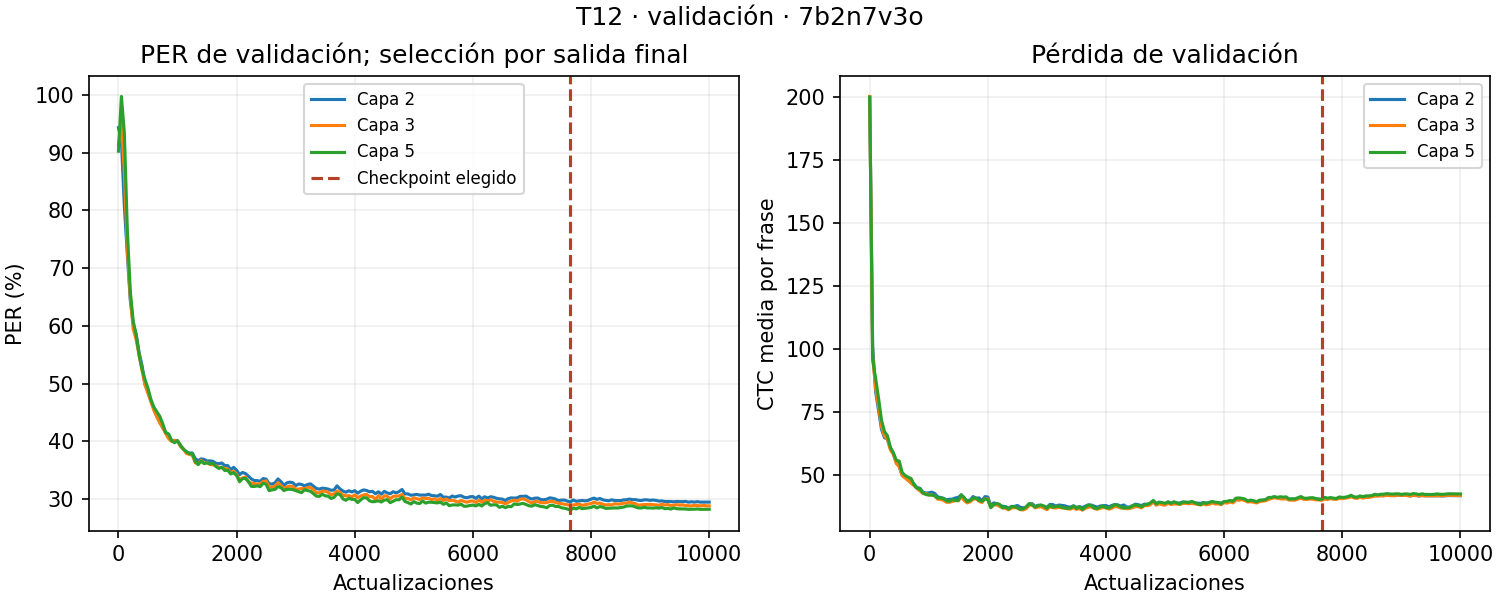

Fuentes, configuración, entorno, log y estado de esta sesión: /content/drive/MyDrive/speech_bci/experimentos/reanudable_t12_20261029_123226_e4586591


In [21]:
#@title 10. Resumen y curvas guardadas (sin entrenar ni evaluar test)
CHECKPOINT_GUARDADO = "" #@param {type:"string"}

selected = globals().get("LAST_CHECKPOINT")
if CHECKPOINT_GUARDADO.strip():
    relative = Path(CHECKPOINT_GUARDADO.strip())
    if relative.is_absolute() or ".." in relative.parts:
        raise ValueError("La ruta debe ser relativa a la carpeta de checkpoints de Drive.")
    selected = CHECKPOINTS / relative
if selected is None:
    for path in sorted((CHECKPOINTS / Path(cfg["salida"]["directorio"]).relative_to("checkpoints")).glob("*/mejor_val.json")):
        print(path.relative_to(CHECKPOINTS))
    print("Indica CHECKPOINT_GUARDADO para consultar uno de los runs.")
else:
    if selected.name != "mejor_val.pt" or not selected.is_file():
        raise ValueError("Selecciona el mejor_val.pt del run de comparación.")
    print("Checkpoint seleccionado por validación:", selected)
    print(json.dumps(json.loads(selected.with_suffix(".json").read_text()), indent=2))
    result_path = selected.parent / "resultado.json"
    if not globals().get("LAST_STATUS", {}).get("completo") or not result_path.is_file():
        print("Reanuda primero el estado confirmado; no se genera un informe de cierre con archivos potencialmente desfasados.")
        latest = selected.parent / "ultimo.json"
        if latest.is_file():
            print("Último paso guardado:", latest.read_text())
    else:
        ejecutar(["scripts/report_speech_training.py", "--run-dir", str(selected.parent)])
        summary_name = "resumen_salidas.json" if cfg["modelo"].get("salidas_intermedias") else "resumen_baseline.json"
        for name in ("resultado.json", summary_name, "curvas_validacion.png"):
            shutil.copyfile(selected.parent / name, RESULTS / name)
        from IPython.display import Image, display
        display(Image(filename=str(RESULTS / "curvas_validacion.png")))
print("Fuentes, configuración, entorno, log y estado de esta sesión:", RESULTS)


## Recargar sin entrenar ni usar test

La celda 11 recarga en un proceso nuevo y exige que las métricas de toda
la validación reproduzcan las guardadas, con las tolerancias fijadas en
`configs/verificacion_checkpoint.yaml`. Después predice la primera frase
de val con las salidas disponibles y verifica las capas ejecutadas.

El baseline dispone de la salida 5, los controles de la 2 o la 3 y la
conjunta de 2/3/5. El comando `run.py --solo-evaluar` evalúa test por defecto;
para inspeccionar val manualmente hay que añadir `--split val`.


In [22]:
#@title 11. Recarga independiente, validación y predicción por perfil
if not globals().get("LAST_STATUS", {}).get("completo"):
    raise RuntimeError("Reanuda y termina normalmente la sesión antes de evaluar o medir estos pesos.")
if selected is None or not selected.is_file():
    raise RuntimeError("Selecciona primero un checkpoint en la celda 10.")
ejecutar(["scripts/verify_speech_checkpoint.py", "--config", CONFIG,
          "--checkpoint", str(selected)])
for name in ("verificacion_recarga.json", "predicciones_val_ejemplo.json"):
    shutil.copyfile(selected.parent / name, RESULTS / name)
verification = json.loads((RESULTS / "verificacion_recarga.json").read_text())
if verification["verified"] is not True or verification["optimizer_steps"] != 0:
    raise RuntimeError("La recarga no quedó verificada.")
print("Recarga correcta, cero actualizaciones y sin test. Paso:", verification["checkpoint_step"])
print("Referencia:", verification["example"]["reference_text"])
for depth, profile in verification["example"]["profiles"].items():
    print("Salida", depth, "· GRU ejecutadas", profile["executed_layers"])
    print(" ".join(profile["hypothesis_phones"]))
print("Evidencia y predicciones:", RESULTS)


wandb: Using wandb-core as the SDK backend.  Please refer to https://wandb.me/wandb-core for more information.
wandb: Currently logged in as: aaurre (aaurre-deusto). Use `wandb login --relogin` to force relogin
wandb: Tracking run with wandb version 0.18.7
wandb: Run data is saved locally in runs/tracking/wandb/run-20261029_124728-taqnwned
wandb: Run `wandb offline` to turn off syncing.
wandb: Syncing run speech_salidas_t4_seed0_colab_recarga_val
wandb: ⭐️ View project at https://wandb.ai/aaurre-deusto/tiiac-2026
wandb: 🚀 View run at https://wandb.ai/aaurre-deusto/tiiac-2026/runs/taqnwned
wandb: - 0.004 MB of 0.004 MB uploaded
wandb: \ 0.004 MB of 0.004 MB uploaded
wandb:                                                                                
wandb: 
wandb: Run history:
wandb: val_recarga/capa_2/completo ▁
wandb: val_recarga/capa_2/ctc_loss ▁
wandb:  val_recarga/capa_2/errores ▁
wandb:  val_recarga/capa_2/fonemas ▁
wandb:   val_recarga/capa_2/frases ▁
wandb:      val_recarga/ca

## Calidad y controles de señal en validación

La celda 12 recarga el checkpoint elegido y evalúa todas las frases de val.
Compara la señal original, la señal normalizada a cero y una permutación
temporal reproducible de cada frase. Conserva etiquetas, sesión y duración.
Los canales se mueven juntos y el padding no se mezcla con señal válida.

Guarda PER/CTC globales y por sesión, un CSV y las predicciones de todas
las frases en JSONL. El PER global suma errores y fonemas; no promedia los
PER de las sesiones. Las salidas de la conjunta comparten el checkpoint
seleccionado por su capa 5. Este diagnóstico no mide latencia de inferencia.


In [17]:
#@title 12. Evaluar calidad por sesión y controles de señal (solo val)
if not globals().get("LAST_STATUS", {}).get("completo"):
    raise RuntimeError("Reanuda y termina normalmente la sesión antes de evaluar o medir estos pesos.")
if selected is None or not selected.is_file():
    raise RuntimeError("Selecciona primero un checkpoint en la celda 10.")
diagnostic_output = RESULTS / ("diagnostico_val_" + uuid4().hex[:8])
ejecutar(["scripts/evaluate_speech.py", "--config", CONFIG, "--checkpoint", str(selected),
          "--split", "val", "--output", str(diagnostic_output)])
diagnostic = json.loads((diagnostic_output / "metricas.json").read_text())
for control, depths in diagnostic["global"].items():
    for depth, metrics in depths.items():
        print(control, "· salida", depth, "· PER", f"{metrics['per']:.2%}",
              f"({metrics['errores']}/{metrics['fonemas']})")
print("Métricas, CSV por sesión y predicciones:", diagnostic_output)


wandb: Using wandb-core as the SDK backend.  Please refer to https://wandb.me/wandb-core for more information.
wandb: Currently logged in as: aaurre (aaurre-deusto). Use `wandb login --relogin` to force relogin
wandb: - Waiting for wandb.init()...
wandb: \ Waiting for wandb.init()...
wandb: Tracking run with wandb version 0.18.7
wandb: Run data is saved locally in runs/tracking/wandb/run-20261029_110945-5u0uh25h
wandb: Run `wandb offline` to turn off syncing.
wandb: Syncing run speech_comparacion_baseline_t4_seed0_colab_diagnostico_val
wandb: ⭐️ View project at https://wandb.ai/aaurre-deusto/tiiac-2026
wandb: 🚀 View run at https://wandb.ai/aaurre-deusto/tiiac-2026/runs/5u0uh25h
wandb: - 0.022 MB of 0.022 MB uploaded
wandb: \ 0.022 MB of 0.022 MB uploaded
wandb: | 0.022 MB of 0.022 MB uploaded
wandb: / 0.022 MB of 0.022 MB uploaded
wandb:                                                                                
wandb: 
wandb: Run history:
wandb:      diagnostico/val/cero/capa_5/co

## Velocidad y memoria con las mismas frases

La celda 13 elige dos ensayos por sesión con la semilla del YAML, sin usar
predicciones. Verifica los .mat y reproduce su normalización de train.
La cohorte y el tamaño de lote serán los mismos para todas las variantes.

Separa carga del modelo, forward con entrada ya preparada en GPU y
procesamiento desde señal cruda en RAM hasta fonemas: normalización,
padding, transferencia, suavizado, red y greedy. La lectura .mat queda
registrada aparte. Calienta cada forma de lote y sincroniza CUDA al medir.

Guarda tiempos por repetición, mediana, p95 y picos de memoria asignada y
reservada por PyTorch. En la conjunta siguen residentes todos los pesos
al elegir 2/3/5; omitir cálculo no elimina las capas de la memoria.
Para comparar resultados se usarán cohortes, hardware, versiones y lote
iguales. Cada checkpoint de las semillas 0/1/2 tendrá su propia medición.


In [18]:
#@title 13. Medir carga, inferencia y pipeline con señal cruda (solo val)
if not globals().get("LAST_STATUS", {}).get("completo"):
    raise RuntimeError("Reanuda y termina normalmente la sesión antes de evaluar o medir estos pesos.")
if selected is None or not selected.is_file():
    raise RuntimeError("Selecciona primero un checkpoint en la celda 10.")
benchmark_output = RESULTS / ("benchmark_val_" + uuid4().hex[:8])
ejecutar(["scripts/benchmark_speech.py", "--config", CONFIG, "--checkpoint", str(selected),
          "--split", "val", "--output", str(benchmark_output)])
benchmark = json.loads((benchmark_output / "benchmark.json").read_text())
print("GPU:", benchmark["runtime"]["hardware"], "· lote:", benchmark["batch_size"])
print("Firma de entradas:", benchmark["inputs"]["input_signature"])
for depth, profile in benchmark["profiles"].items():
    print("Salida", depth, "· mediana forward", f"{profile['forward']['p50_ms']:.3f} ms",
          "· señal cruda→fonemas", f"{profile['raw_to_phones']['p50_ms']:.3f} ms")
print("JSON y CSV de mediciones:", benchmark_output)


wandb: Using wandb-core as the SDK backend.  Please refer to https://wandb.me/wandb-core for more information.
wandb: Currently logged in as: aaurre (aaurre-deusto). Use `wandb login --relogin` to force relogin
wandb: - Waiting for wandb.init()...
wandb: \ Waiting for wandb.init()...
wandb: Tracking run with wandb version 0.18.7
wandb: Run data is saved locally in runs/tracking/wandb/run-20261029_111015-38eifndq
wandb: Run `wandb offline` to turn off syncing.
wandb: Syncing run speech_comparacion_baseline_t4_seed0_colab_benchmark
wandb: ⭐️ View project at https://wandb.ai/aaurre-deusto/tiiac-2026
wandb: 🚀 View run at https://wandb.ai/aaurre-deusto/tiiac-2026/runs/38eifndq
Benchmark: t12.2022.04.28, 2 ensayos crudos verificados.
Benchmark: t12.2022.05.05, 2 ensayos crudos verificados.
Benchmark: t12.2022.05.17, 2 ensayos crudos verificados.
Benchmark: t12.2022.05.19, 2 ensayos crudos verificados.
Benchmark: t12.2022.05.24, 2 ensayos crudos verificados.
Benchmark: t12.2022.05.26, 2 ensay